# Choke Points in LLM Reasoning - results walkthrough

This notebook is the demonstration copy of the project. It **recomputes nothing**: every
cell loads a file written by the pipeline (`make all`) and explains it. Numbers are printed
from the files, never typed into the prose, so the notebook stays correct if the pipeline
is re-run.

Suggested order when presenting: the problem -> architecture (Fig. 1) -> where errors start
(F4) -> how early failure is predictable (F7) -> what the detector cannot do yet (timing,
transfer) -> what was not run.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES, FIGURES, DIAGRAMS = ROOT / "results/tables", ROOT / "results/figures", ROOT / "docs/diagrams/rendered"
values = json.loads((ROOT / "results/paper_values.json").read_text())["placeholders"]
V = lambda key: values[key]["value"]
manifest = [json.loads(line) for line in (ROOT / "results/manifest.json").read_text().splitlines() if line.strip()]
status = {}
for row in manifest:
    status[row["stage"]] = row["status"]
pd.Series(status, name="status").to_frame()

,status
01_download_data,OK
02_preprocess,OK
03_run_eda,OK
04_run_statistics,OK
05_train_baselines,OK
06_extract_activations,SKIPPED_GPU_ABSENT
07_train_probes,SKIPPED_GPU_ABSENT
08_lead_time_analysis,OK
09_simulate_intervention,OK
10_build_report,OK


## 0. The system being studied

Phase I scores each reasoning step with a detector; Phase II would intervene only when the
risk crosses a threshold. This build evaluates Phase I with text-based detectors (the
hidden-state probe needs a GPU) and only *simulates* Phase II.

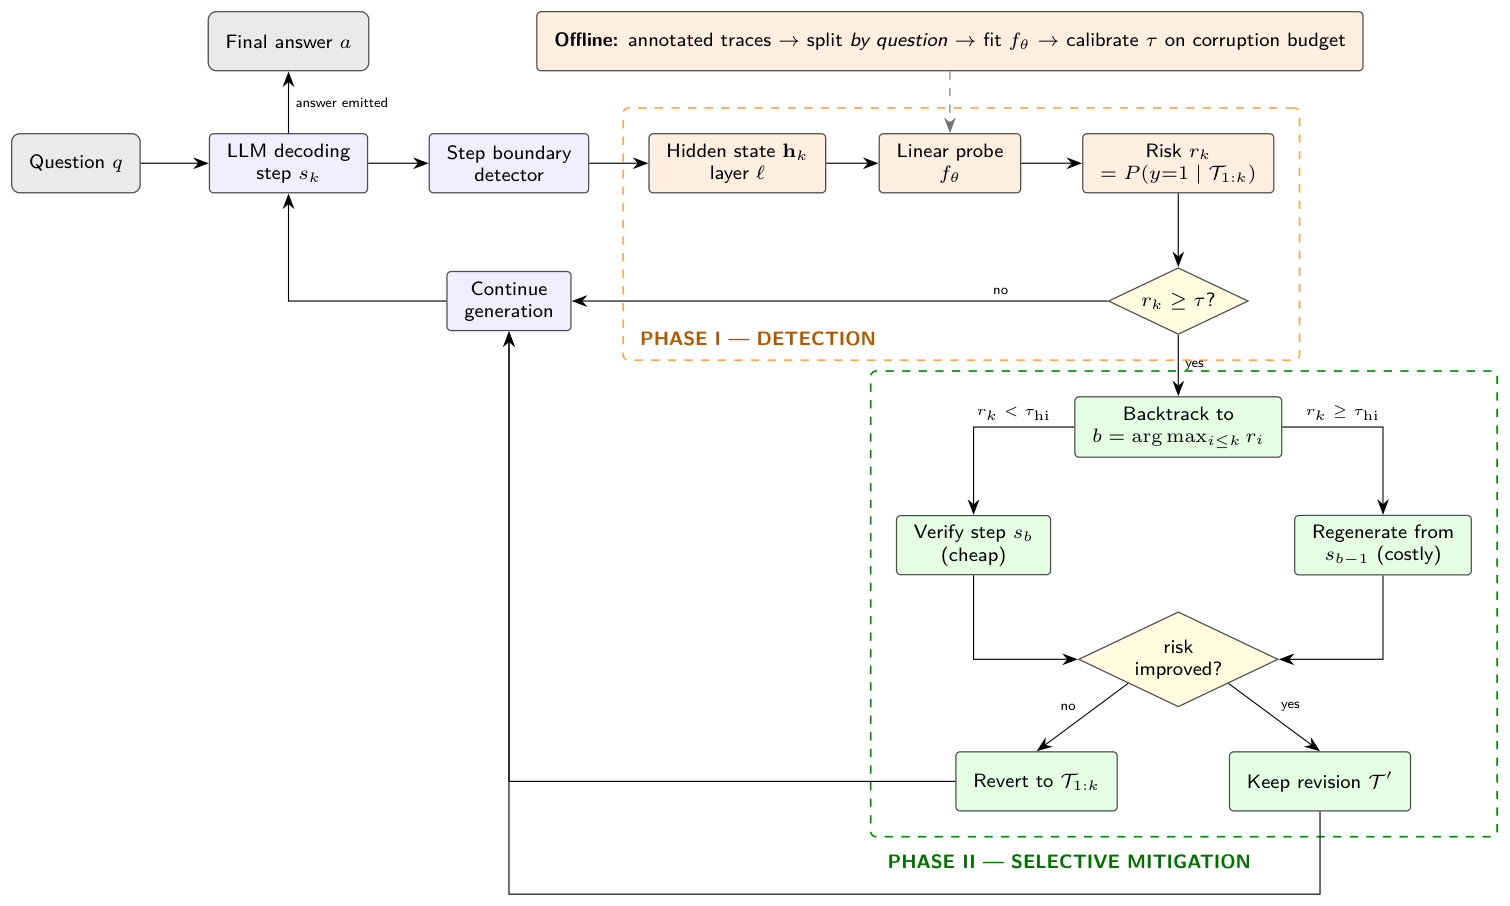

In [2]:
display(Image(str(DIAGRAMS / "architecture.png"), width=900))

A real ProcessBench trace (chosen by a fixed rule in `docs/diagrams/render.py`) with its
first erroneous step highlighted:

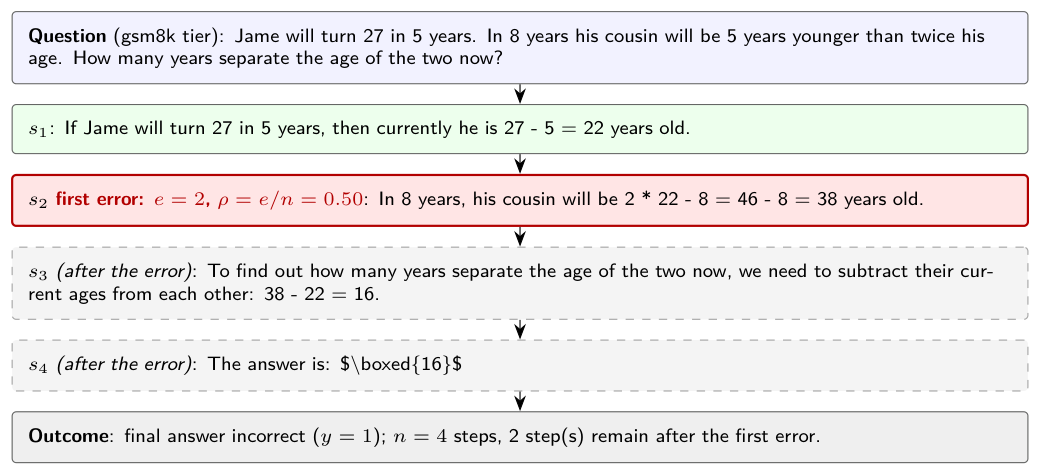

In [3]:
display(Image(str(DIAGRAMS / "worked_example_processbench.png"), width=800))

## 1. The data and its quality

Two labels matter and they are not the same: a **process error** (a human found a wrong
step) and an **incorrect final answer** (the paper's target y).

,ProcessBench
n_raw,3400
n_clean,3400
dropped_by_p5,0
n_questions,2842
duplicate_trace_ids,0
frac_has_error,0.653235
frac_answer_incorrect,0.5
unexpected_missing,{}


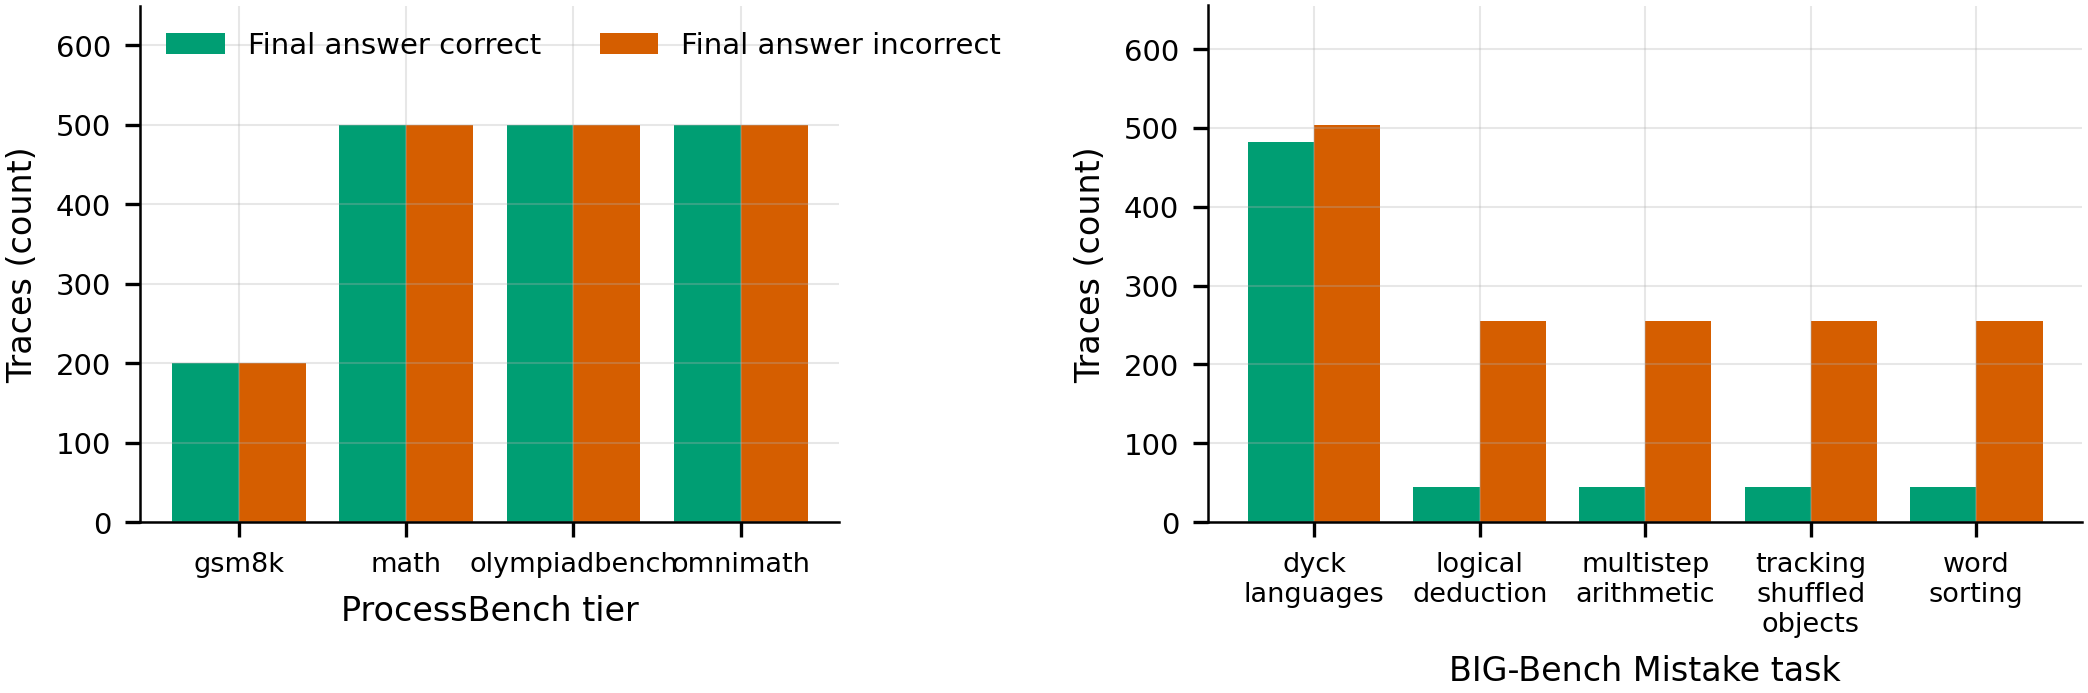

In [4]:
quality = json.loads((TABLES / "processed_traces_quality_report.json").read_text())
display(pd.Series(quality, name="ProcessBench").to_frame())
display(Image(str(FIGURES / "fig1_class_balance.png"), width=850))

## 2. Where failures originate (E1)

`mean_relative_onset` is rho = e/n averaged over traces with an error;
`expected_mean_rho_uniform_step` is what it would be if the error step were uniform over
each trace's own steps; `mean_steps_remaining` bounds the window for intervention.

In [5]:
desc = pd.read_csv(TABLES / "table1_descriptive.csv")
desc[["subset", "n_traces", "pct_erroneous", "pct_answer_incorrect", "median_steps", "mean_relative_onset",
      "expected_mean_rho_uniform_step", "pct_errors_first_half", "pct_errors_final_step",
      "expected_pct_final_step_uniform", "mean_steps_remaining"]].round(3)

,subset,n_traces,pct_erroneous,pct_answer_incorrect,median_steps,mean_relative_onset,expected_mean_rho_uniform_step,pct_errors_first_half,pct_errors_final_step,expected_pct_final_step_uniform,mean_steps_remaining
0,gsm8k,400,51.750,50.0,5.0,0.546,0.604,55.072,7.729,20.839,2.483
1,math,1000,59.400,50.0,6.0,0.502,0.591,57.912,5.387,18.100,3.601
2,olympiadbench,1000,66.100,50.0,8.0,0.511,0.568,56.884,4.387,13.553,4.534
3,omnimath,1000,75.900,50.0,7.0,0.478,0.569,61.660,1.845,13.839,4.610
4,ALL,3400,65.324,50.0,7.0,0.500,0.578,58.622,4.097,15.546,4.119


## 3. Headline figure (F4) and the statistical test behind it (E2)

Left: observed histogram of rho against the count expected if errors were spread evenly
over steps. Right: cumulative curves against the same null and against Uniform(0,1).

Read the two tests together. KS against Uniform(0,1) rejects, but so would evenly spread
errors, because rho = e/n takes only a few values on short traces. The Monte Carlo test
against the correct discrete null is the one that supports (or not) the claim that errors
come early.

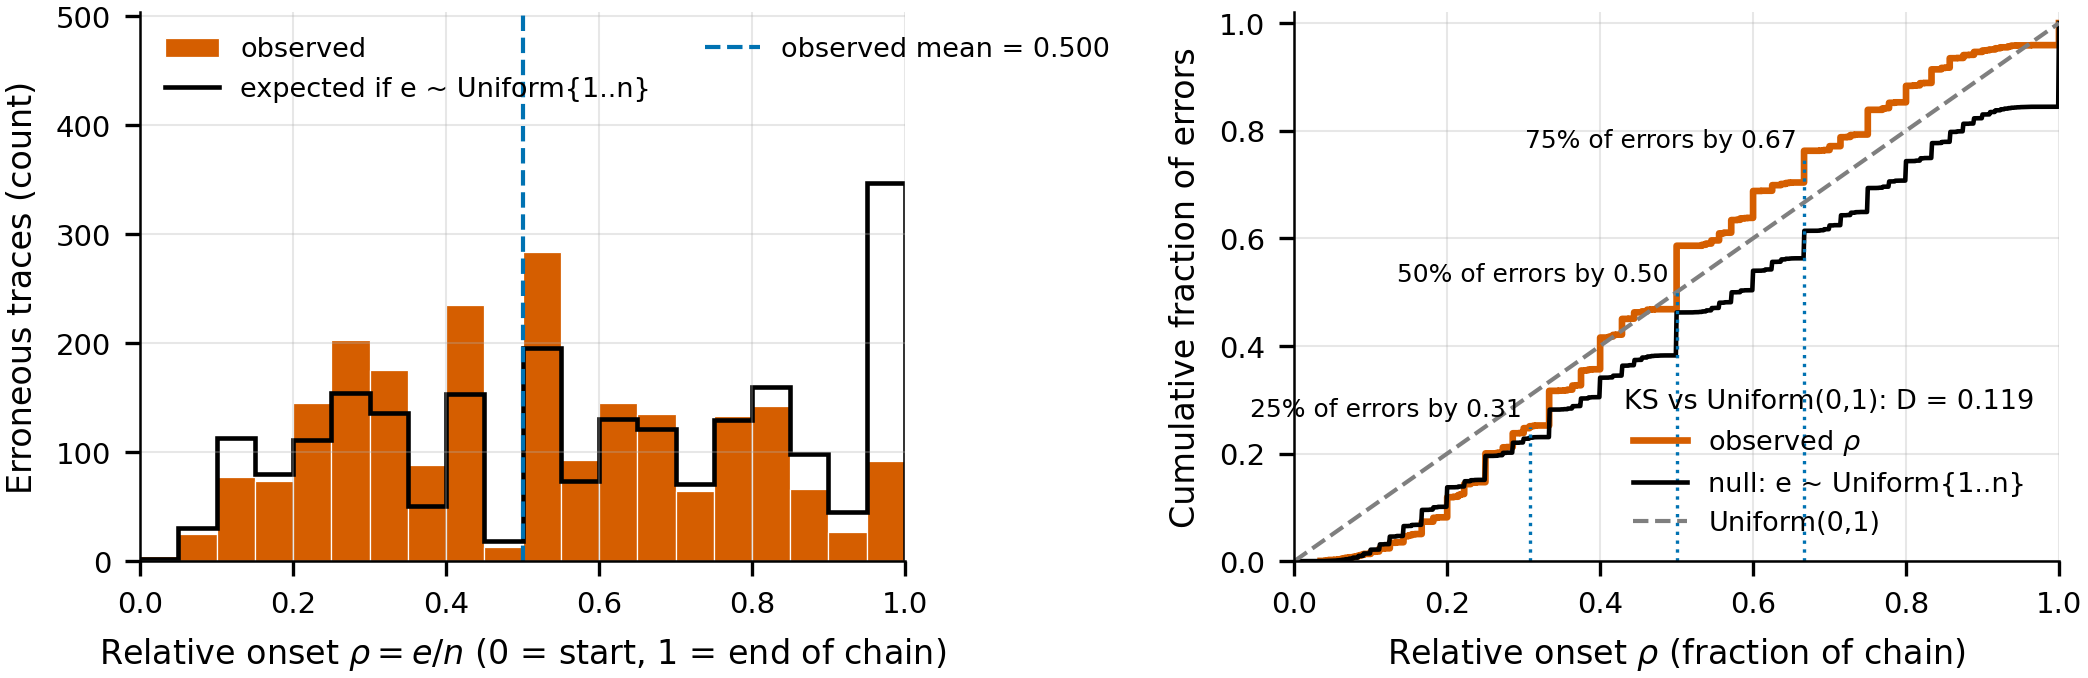

- KS vs Uniform(0,1): D = 0.119, p = 1.2e-27
- KS-to-uniform expected under the discrete null: mean 0.155, 95th percentile 0.167
- Distance to the discrete null: D = 0.149 (null 95th percentile 0.026), Monte Carlo p = 0.0010
- Mean rho 0.500 vs 0.578 under the null: earlier than null
- Kruskal-Wallis across tiers: H = 14.50, p = 0.002, eta^2 = 0.005

In [6]:
display(Image(str(FIGURES / "fig4_relative_error_position_HEADLINE.png"), width=900))
stats = json.loads((TABLES / "table_stats_tests.json").read_text())
ks, null = stats["ks_uniform"], stats["ks_discrete_uniform_step_null"]
display(Markdown(
    f"- KS vs Uniform(0,1): D = {ks['statistic_D']:.3f}, p = {ks['p_value']:.1e}\n"
    f"- KS-to-uniform expected under the discrete null: mean {null['null_D_uniform_mean']:.3f}, "
    f"95th percentile {null['null_D_uniform_q95']:.3f}\n"
    f"- Distance to the discrete null: D = {null['observed_D_vs_null']:.3f} (null 95th percentile "
    f"{null['null_D_vs_null_q95']:.3f}), Monte Carlo p = {null['p_value']:.4f}\n"
    f"- Mean rho {null['observed_mean_rho']:.3f} vs {null['null_mean_rho']:.3f} under the null: {null['direction']}\n"
    f"- Kruskal-Wallis across tiers: H = {stats['kruskal_tiers']['H']:.2f}, "
    f"p = {stats['kruskal_tiers']['p_value']:.3f}, eta^2 = {stats['kruskal_tiers']['eta_squared']:.3f}"))

## 4. The length confound (F2)

If failing traces are simply longer, any detector that can see length will look good.
Mann-Whitney r > 0 means erroneous traces are longer.

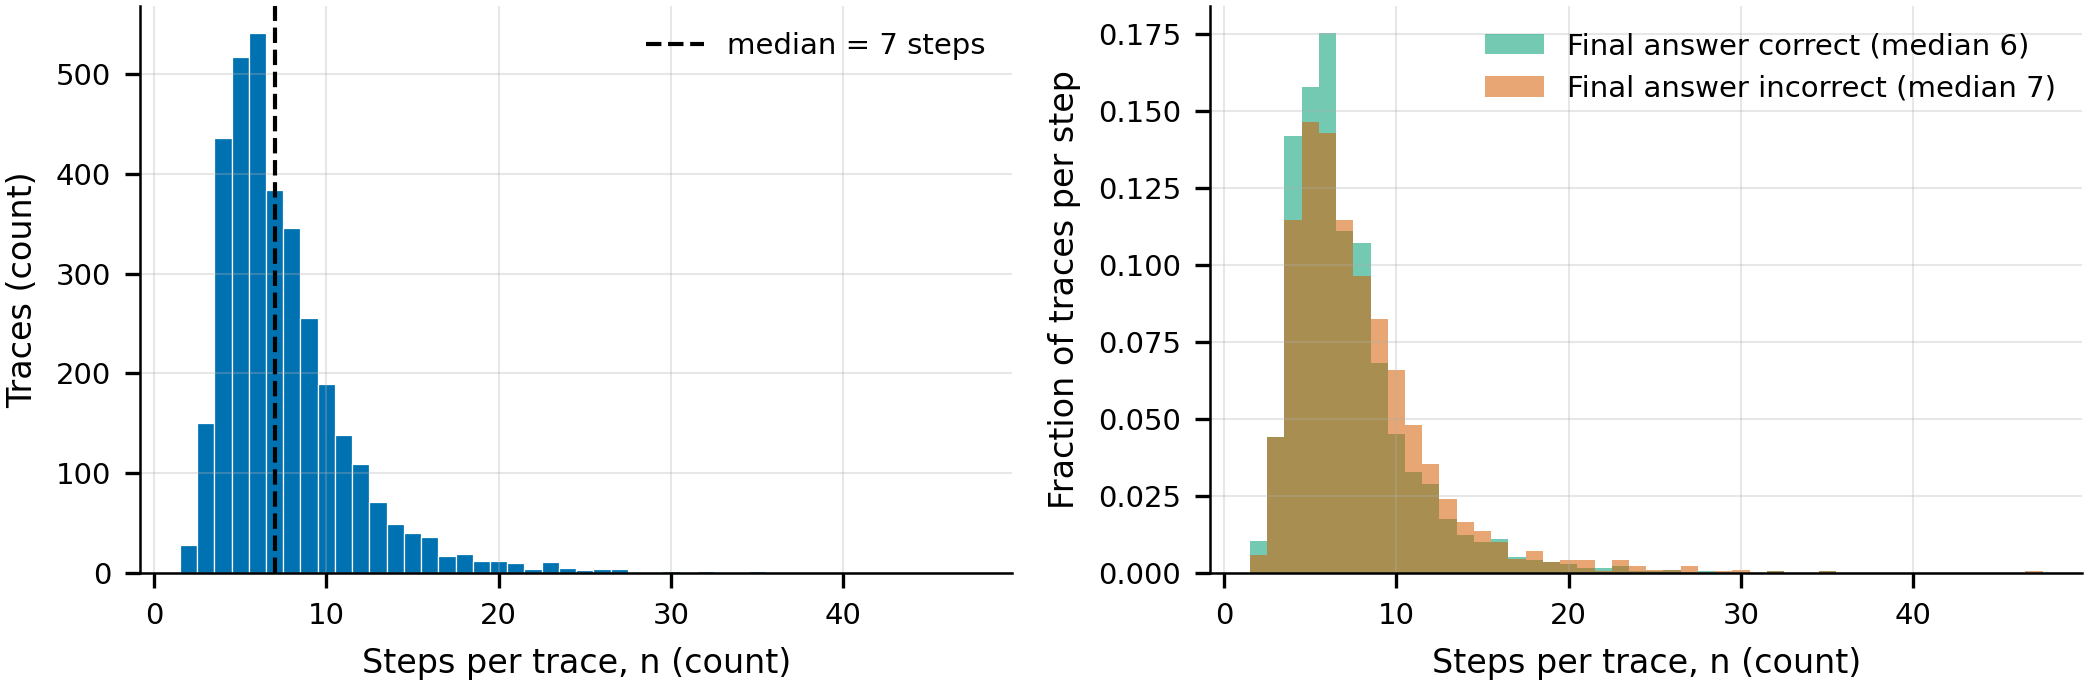

,U,p_value,rank_biserial_r,median_len_erroneous,median_len_correct,n_erroneous,n_correct
mann_whitney_length_process_error,1538275.0,2.655202e-17,0.174902,7.0,6.0,2221.0,1179.0
mann_whitney_length_answer_incorrect,1579514.0,2.236411e-06,0.093089,7.0,6.0,1700.0,1700.0


In [7]:
display(Image(str(FIGURES / "fig2_chain_length.png"), width=900))
pd.DataFrame({k: v for k, v in stats.items() if k.startswith("mann_whitney")}).T

## 5. Core result: how early is failure predictable? (E3, F7)

AUROC on questions never seen in training, as a function of the fraction of the chain
observed. The grey length-only curve is the confound floor: a prefix of k = ceil(f n) steps
reveals n.

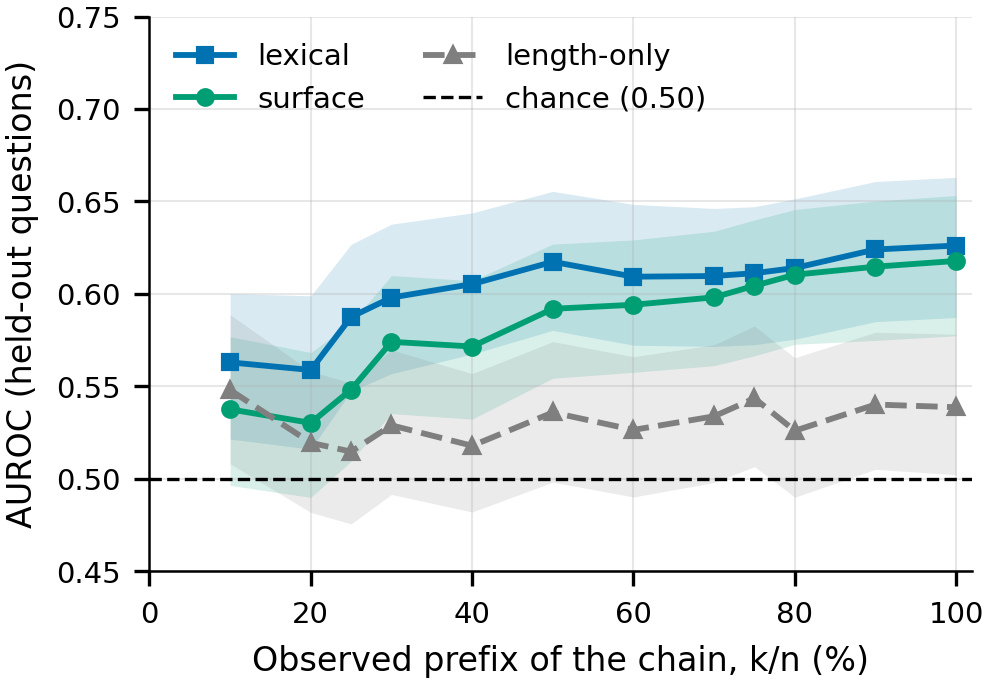

representation,length-only,lexical,surface,surface-GRU,surface-MLP
fraction_observed,,,,,
0.10,0.548,0.563,0.538,0.535,0.546
0.20,0.519,0.559,0.530,0.516,0.534
0.25,0.515,0.588,0.548,0.543,0.554
0.30,0.529,0.598,0.574,0.571,0.578
0.40,0.518,0.605,0.572,0.568,0.577
0.50,0.536,0.617,0.592,0.563,0.591
0.60,0.526,0.609,0.594,0.576,0.605
0.70,0.534,0.610,0.598,0.552,0.599
0.75,0.543,0.611,0.604,0.560,0.604


Abstract numbers: lexical AUROC 0.588 [0.547, 0.627] at 25%, 0.626 at 100%; surface floor 0.618; length-only 0.539.

In [8]:
display(Image(str(FIGURES / "fig7_auroc_vs_prefix_KEY.png"), width=600))
curve = pd.read_csv(TABLES / "table2_prefix_auroc.csv")
target = curve["target"].iloc[0]
view = curve[curve["target"] == target].pivot(index="fraction_observed", columns="representation", values="auroc")
display(view.round(3))
display(Markdown(f"Abstract numbers: lexical AUROC {V('AUROC_lexical_25')} {V('AUROC_lexical_25_ci')} at 25%, "
                 f"{V('AUROC_lexical_100')} at 100%; surface floor {V('AUROC_surface_100')}; "
                 f"length-only {V('AUROC_length_100')}."))

All detectors at the full prefix, and the status of representations that could not run:

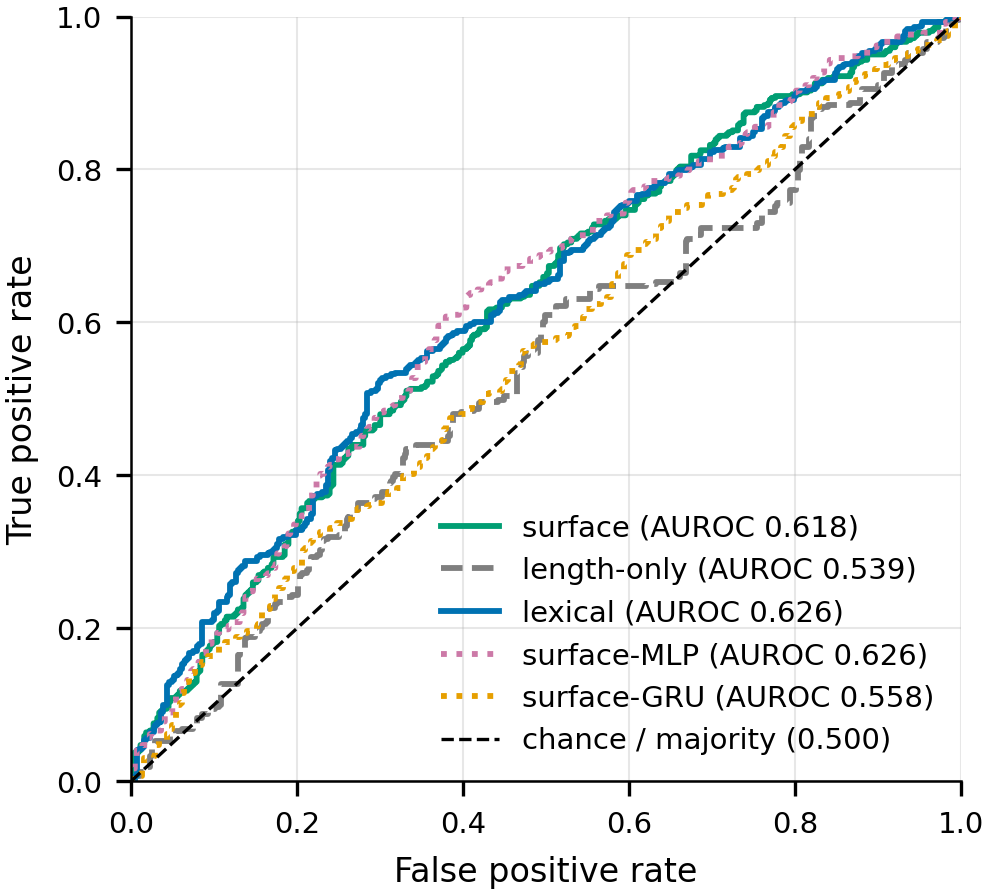

,representation,status,auroc_full_prefix,note
0,majority-class,OK,0.5,constant score = train prevalence 0.504
1,uncertainty (token entropy / logit margin),NOT_RUN,NaN,ProcessBench stores step text only; no token l...
2,hidden-state (linear probe),NOT_RUN,NaN,Requires stage 06 activations (GPU); see table...


In [9]:
display(Image(str(FIGURES / "fig6_roc_all_representations.png"), width=500))
pd.read_csv(TABLES / "table2_representation_status.csv")

## 6. Does the alarm come before the error, and only when needed? (E5, F9)

A positive lead time is only useful if the alarm is rare on traces without errors. Compare
`alarm_rate` with `false_alarm_rate_error_free` at each threshold.

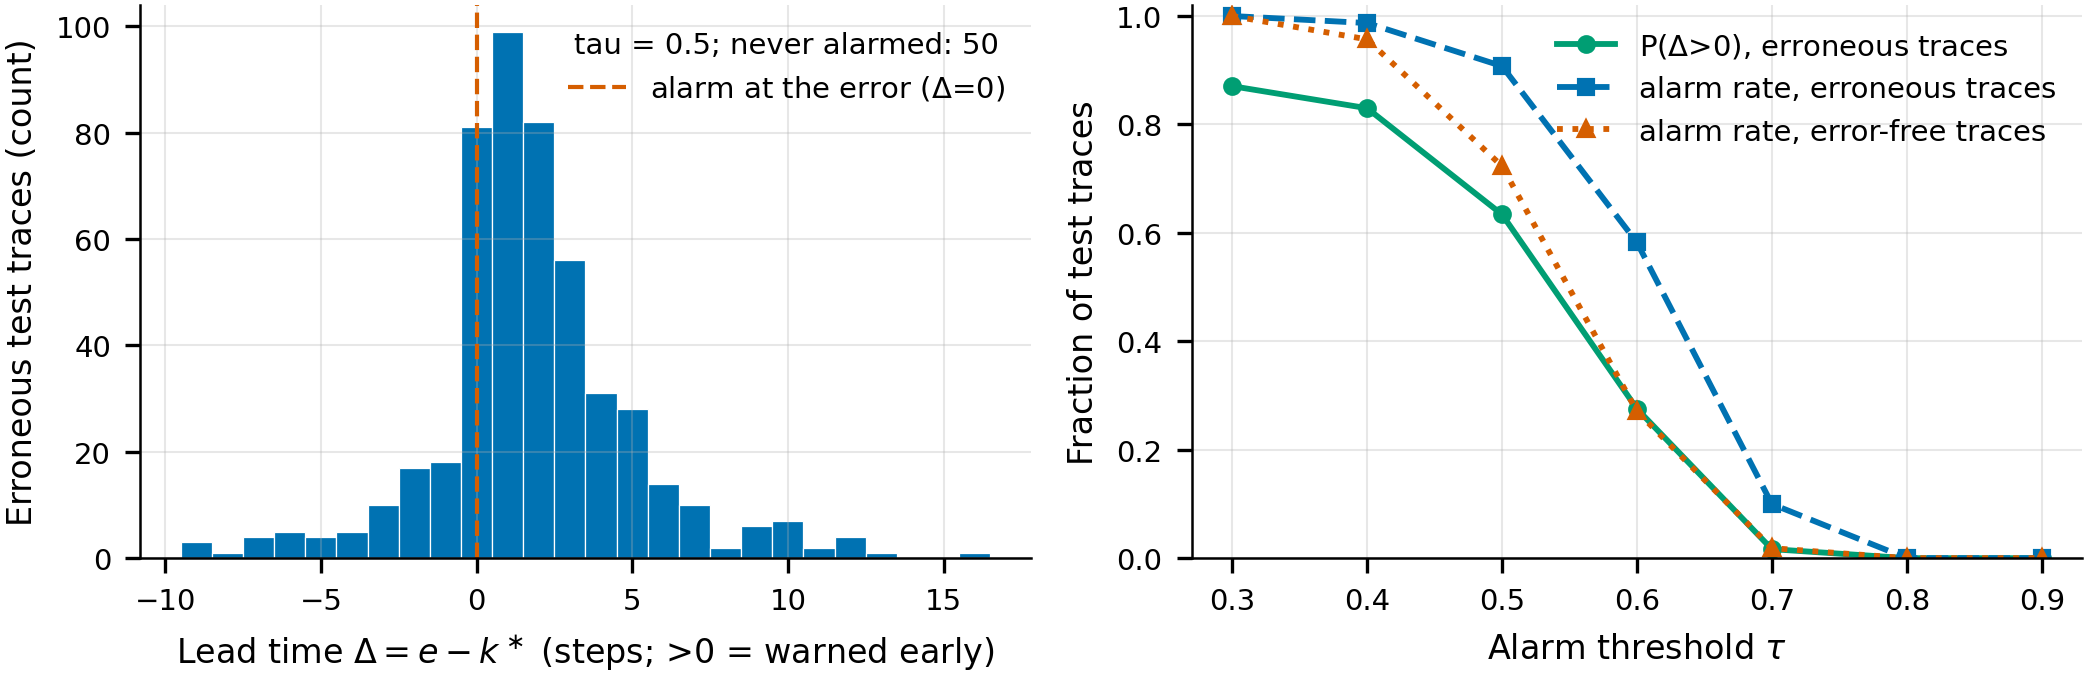

,threshold,n_traces,alarm_rate,frac_warned_before_error,frac_alarm_at_error,median_delta,delta_q25,delta_q75,false_alarm_rate_error_free,n_error_free
0,0.3,541,1.000,0.871,0.129,2.0,1.0,4.0,1.000,325
1,0.4,541,0.987,0.830,0.135,2.0,1.0,4.0,0.957,325
2,0.5,541,0.908,0.634,0.150,1.0,0.0,3.0,0.723,325
3,0.6,541,0.582,0.275,0.111,0.0,-2.0,2.0,0.271,325
4,0.7,541,0.100,0.017,0.011,-2.0,-6.0,0.0,0.018,325
5,0.8,541,0.000,0.000,0.000,NaN,NaN,NaN,0.000,325
6,0.9,541,0.000,0.000,0.000,NaN,NaN,NaN,0.000,325


In [10]:
display(Image(str(FIGURES / "fig9_lead_time.png"), width=900))
pd.read_csv(TABLES / "table_lead_summary.csv").round(3)

## 7. Can the risk scores be used as probabilities? (E6, F10)

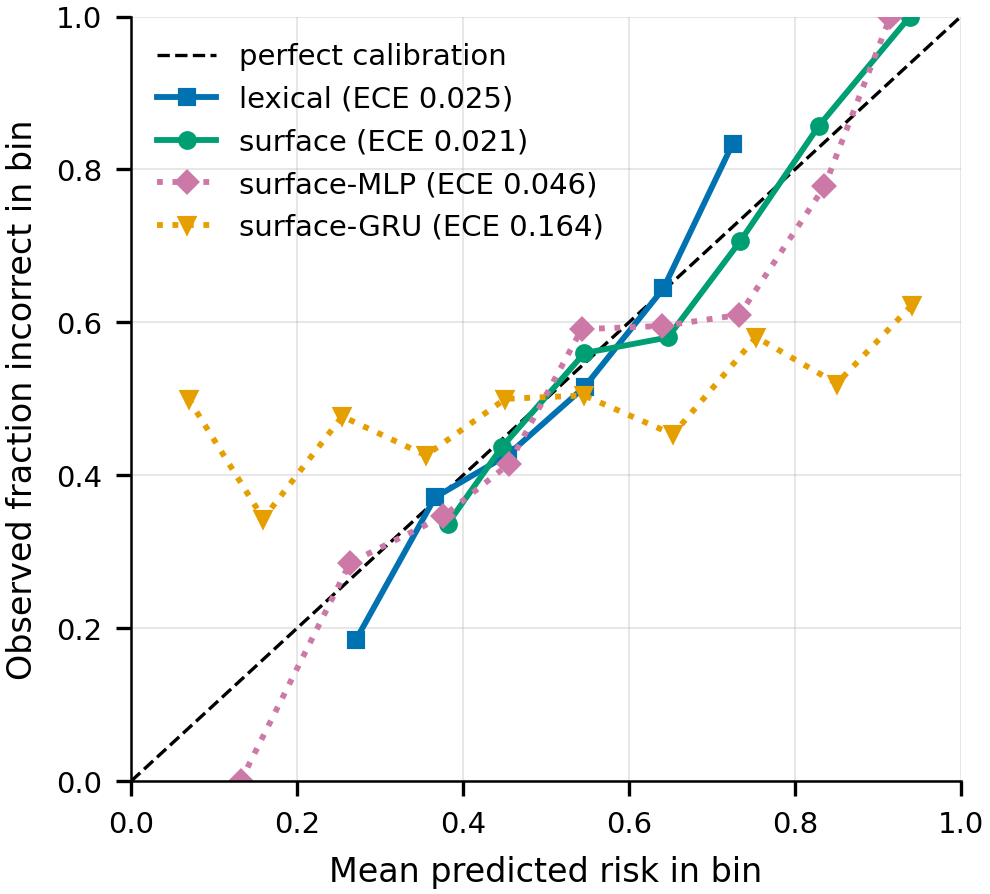

,detector,ece,n_test
0,lexical,0.0253,866
1,surface,0.0210,866
2,surface-MLP,0.0456,866
3,surface-GRU,0.1643,866


In [11]:
display(Image(str(FIGURES / "fig10_reliability.png"), width=500))
pd.read_csv(TABLES / "table_calibration_ece.csv").round(4)

## 8. Does the detector transfer beyond maths? (E7, F13)

Trained on ProcessBench, evaluated on BIG-Bench Mistake. AUROC below 0.5 means the ranking
is inverted on that task.

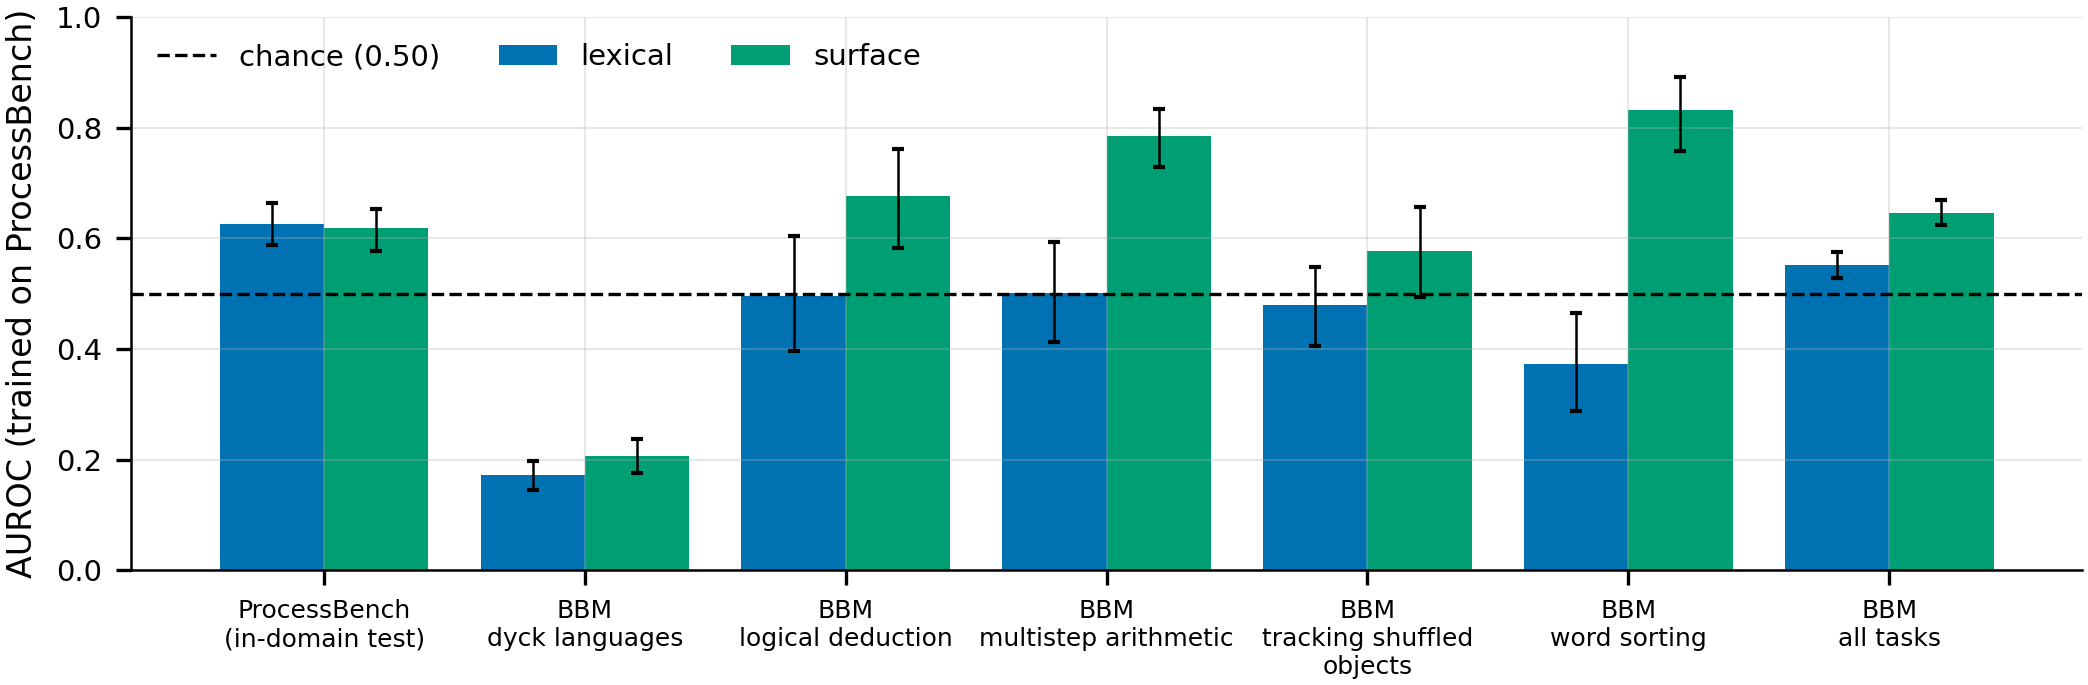

,representation,evaluation_domain,auroc,ci_lo,ci_hi,positive_rate,auroc_drop
0,lexical,ProcessBench (in-domain test),0.626,0.587,0.663,0.488,0.000
1,lexical,BBM: dyck_languages,0.172,0.146,0.197,0.511,0.454
2,lexical,BBM: logical_deduction,0.495,0.397,0.603,0.850,0.131
3,lexical,BBM: multistep_arithmetic,0.502,0.413,0.593,0.850,0.124
4,lexical,BBM: tracking_shuffled_objects,0.480,0.406,0.548,0.850,0.146
5,lexical,BBM: word_sorting,0.372,0.288,0.466,0.850,0.254
6,lexical,BBM: all tasks,0.552,0.528,0.576,0.697,0.074
7,surface,ProcessBench (in-domain test),0.618,0.577,0.653,0.488,0.000
8,surface,BBM: dyck_languages,0.206,0.176,0.237,0.511,0.412
9,surface,BBM: logical_deduction,0.676,0.583,0.761,0.850,-0.058


In [12]:
display(Image(str(FIGURES / "fig13_transfer.png"), width=900))
pd.read_csv(TABLES / "table_transfer.csv")[["representation", "evaluation_domain", "auroc", "ci_lo", "ci_hi",
                                              "positive_rate", "auroc_drop"]].round(3)

## 9. Intervention (E8) - a simulation, not a result

Alarms and costs come from the data; what an intervention achieves is **assumed** (the
parameters are printed below). Use this only to explain how recovery and corruption would
be traded off, never as evidence that intervention works.

{'p_verify_repair': 0.4, 'p_verify_corrupt': 0.05, 'p_regen_repair': 0.6, 'p_regen_corrupt': 0.1, 'p_revert_catches_corruption': 0.5, 'verify_tokens': 32, 'chars_per_token': 4.0}


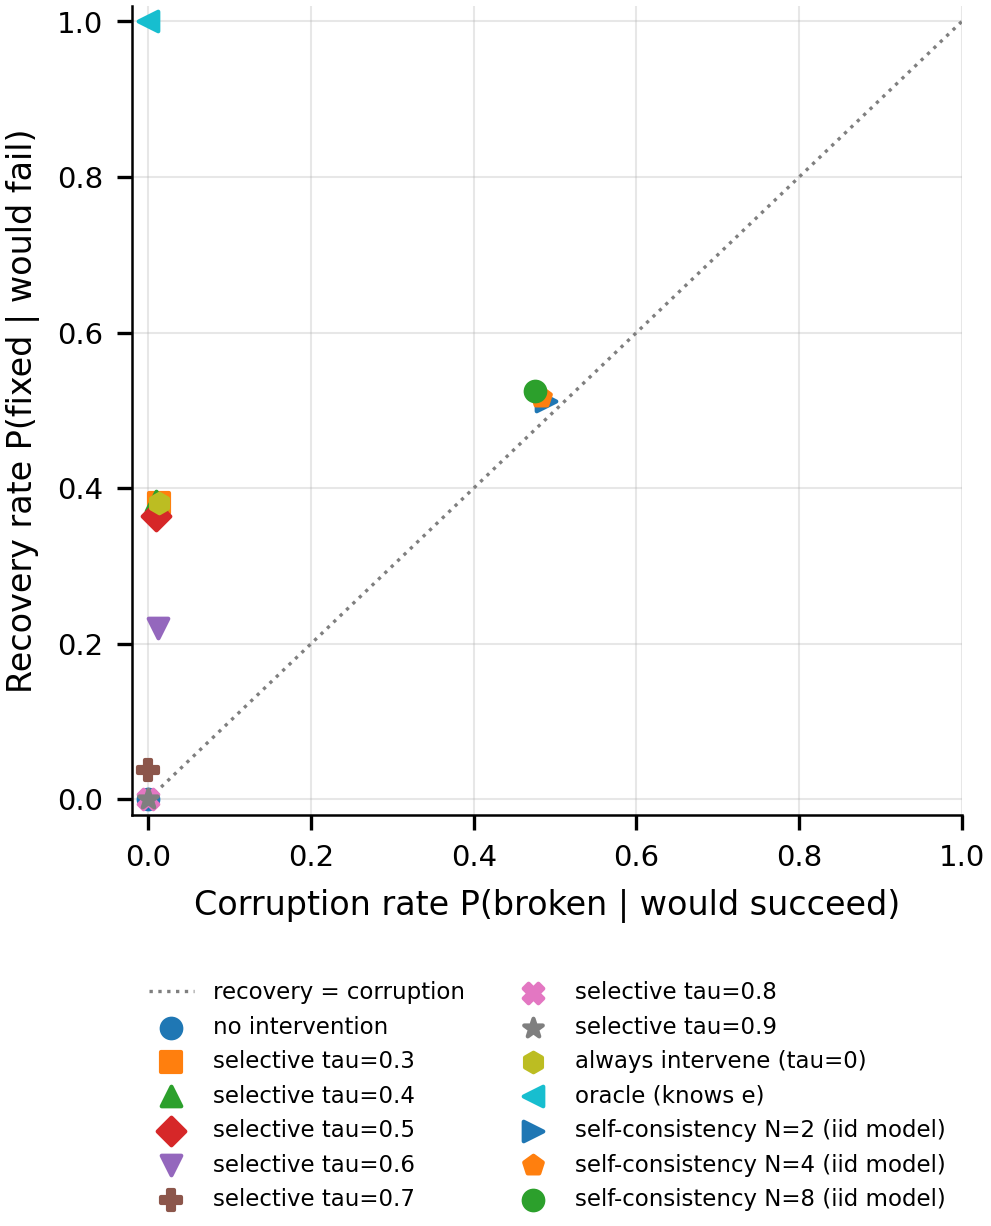

,policy,recovery_rate,corruption_rate,net_benefit,net_accuracy_change,intervention_rate,extra_tokens_per_question,n_traces
0,no intervention,0.000,0.000,0.000,0.000,0.000,0.000,866
1,selective tau=0.3,0.381,0.014,0.367,0.179,1.000,32.000,866
2,selective tau=0.4,0.383,0.009,0.374,0.182,0.976,31.224,866
3,selective tau=0.5,0.364,0.009,0.355,0.173,0.838,26.827,866
4,selective tau=0.6,0.220,0.011,0.209,0.102,0.465,14.891,866
5,selective tau=0.7,0.038,0.000,0.038,0.018,0.069,2.217,866
6,selective tau=0.8,0.000,0.000,0.000,0.000,0.000,0.000,866
7,selective tau=0.9,0.000,0.000,0.000,0.000,0.000,0.000,866
8,always intervene (tau=0),0.381,0.014,0.367,0.179,1.000,32.000,866
9,oracle (knows e),1.000,0.000,1.000,0.488,0.488,161.057,866


In [13]:
print(json.loads((TABLES / "table_intervention_assumptions.json").read_text()))
display(Image(str(FIGURES / "fig11_recovery_vs_corruption.png"), width=450))
pd.read_csv(TABLES / "table_intervention.csv").round(3)

## 10. What did not run

Hidden-state probing (E4) needs a CUDA GPU; figures F8 and F14 are explicit NOT RUN panels.
Run `make activations probes` on a GPU machine, then `make report`, and re-run this notebook.

06_extract_activations: SKIPPED_GPU_ABSENT
07_train_probes: SKIPPED_GPU_ABSENT


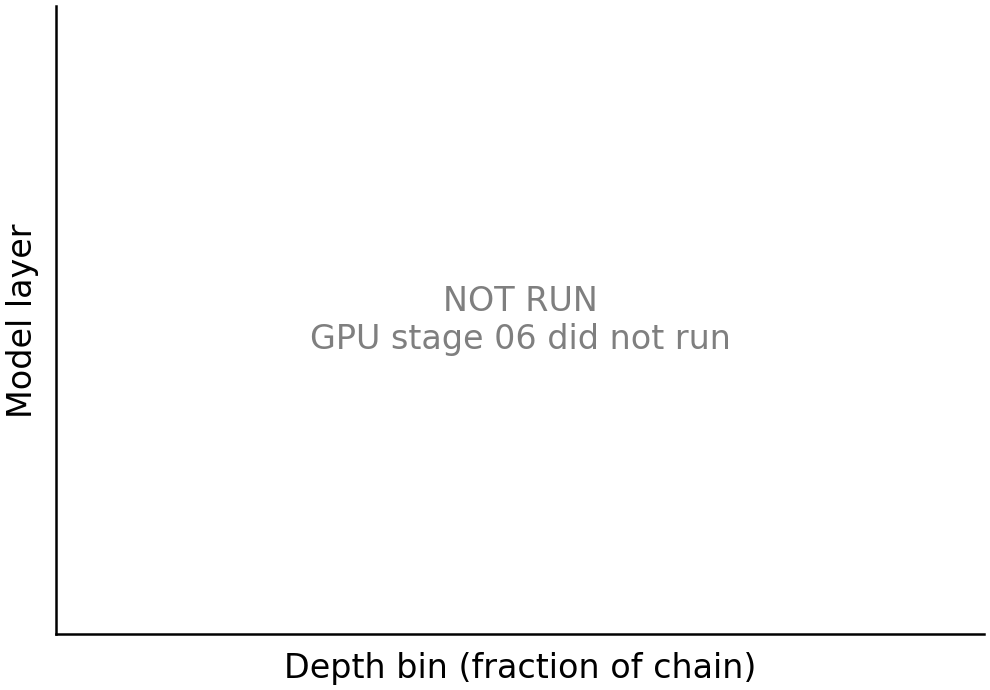

In [14]:
print("06_extract_activations:", status.get("06_extract_activations"))
print("07_train_probes:", status.get("07_train_probes"))
display(Image(str(FIGURES / "fig8_layer_depth_heatmap.png"), width=400))